# ITS66604 Individual Assignment — Question 17
## Estimating Concrete Compressive Strength from Mix Ingredients

**Dataset (Kaggle):** https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set
**Original source:** Yeh, I-C. (1998). UCI Machine Learning Repository, https://doi.org/10.24432/C5PK67

Task: predict compressive strength (MPa, continuous) from seven ingredient amounts (kg/m³) and curing age (days).
This is a **supervised regression** problem. The notebook runs top to bottom with `data/concrete_data.csv` next to it.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, KFold,
                                     cross_validate, GridSearchCV, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import sklearn

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("data/concrete_data.csv")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 2.3.3


## 1. Load and inspect the data
The raw CSV has trailing spaces in values and in one column name, so whitespace is stripped on load.

In [2]:
df_raw = pd.read_csv(DATA, skipinitialspace=True)
df_raw.columns = df_raw.columns.str.strip()
TARGET = "concrete_compressive_strength"
INGREDIENTS = ["cement", "blast_furnace_slag", "fly_ash", "water",
               "superplasticizer", "coarse_aggregate", "fine_aggregate"]
FEATURES = INGREDIENTS + ["age"]

print("Shape:", df_raw.shape)
print("Missing values:", int(df_raw.isna().sum().sum()))
df_raw.describe().T.round(2)

Shape: (1030, 9)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
blast_furnace_slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
coarse_aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_aggregate,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
concrete_compressive_strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


## 2. Data quality checks
* **Exact duplicate rows** add no information and over-weight some samples.
* **Zeros** in slag, fly ash and superplasticizer mean "not used in this mix" (a structural zero), not missing data.
* **Repeated mixes**: the same recipe is tested at several ages. Rows from one recipe are not independent, which matters for how the data is split.

In [3]:
n_dup = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows removed: {n_dup}  ->  {len(df)} rows remain")

for c in ["blast_furnace_slag", "fly_ash", "superplasticizer"]:
    print(f"{c:>20}: {(df[c] == 0).mean():.0%} of rows are 0 (ingredient not used)")

df["mix_id"] = df.groupby(INGREDIENTS).ngroup()
mix_size = df.groupby("mix_id").size()
print(f"\nUnique mixes: {df.mix_id.nunique()}")
print(f"Rows whose mix appears more than once: {mix_size[mix_size > 1].sum()} ({mix_size[mix_size > 1].sum() / len(df):.0%})")

# Same mix AND same age but different measured strength (repeated tests)
rep = df.groupby(FEATURES)[TARGET].agg(["count", "min", "max"])
rep = rep[rep["count"] > 1].assign(range_MPa=lambda d: d["max"] - d["min"])
print(f"Repeated tests (same mix and age, different strength): {len(rep)} groups from "
      f"{rep.reset_index()[INGREDIENTS].drop_duplicates().shape[0]} mixes")
print(rep.round(2).reset_index()[["cement", "age", "count", "min", "max", "range_MPa"]].to_string(index=False))
print("Note: one pair differs by about 33 MPa at 7 days - a likely recording anomaly. "
      "It is kept (no evidence to justify removal) and flagged in the report.")

print("\nAge distribution (days: rows):")
print(df.age.value_counts().sort_index().to_dict())

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr_out = df[(df[TARGET] < q1 - 1.5 * (q3 - q1)) | (df[TARGET] > q3 + 1.5 * (q3 - q1))]
print(f"\nTarget skewness: {df[TARGET].skew():.2f}; IQR outliers in target: {len(iqr_out)}")
iqr_out[FEATURES + [TARGET]]

Exact duplicate rows removed: 25  ->  1005 rows remain
  blast_furnace_slag: 47% of rows are 0 (ingredient not used)
             fly_ash: 54% of rows are 0 (ingredient not used)
    superplasticizer: 38% of rows are 0 (ingredient not used)

Unique mixes: 427
Rows whose mix appears more than once: 759 (76%)
Repeated tests (same mix and age, different strength): 9 groups from 3 mixes
 cement  age  count   min   max  range_MPa
  359.0    3      2 23.64 25.12       1.48
  359.0    7      2 35.75 38.61       2.86
  359.0   28      2 59.49 62.94       3.45
  359.0   56      2 66.78 68.75       1.97
  362.6    7      2 22.90 55.90      33.00
  446.0    3      3 23.35 35.36      12.01
  446.0    7      3 38.02 52.01      13.99
  446.0   28      3 44.42 57.03      12.61
  446.0   56      3 55.25 61.07       5.82
Note: one pair differs by about 33 MPa at 7 days - a likely recording anomaly. It is kept (no evidence to justify removal) and flagged in the report.

Age distribution (days: rows):
{1

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
136,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,77.30
137,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,80.20
141,389.9,189.0,0.0,145.9,22.0,944.7,755.8,56,79.40
154,362.6,189.0,0.0,164.9,11.6,944.7,755.8,91,79.30
158,389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,82.60
357,315.0,137.0,0.0,145.0,5.9,1130.0,745.0,28,81.75
359,451.0,0.0,0.0,165.0,11.3,1030.0,745.0,28,78.80


## 3. Exploratory analysis
Water-to-cement ratio (w/c) is a classic driver of strength in concrete engineering (Abrams' law). It is not a raw column,
but its relationship with strength shows that ingredients act **jointly**, not one by one.

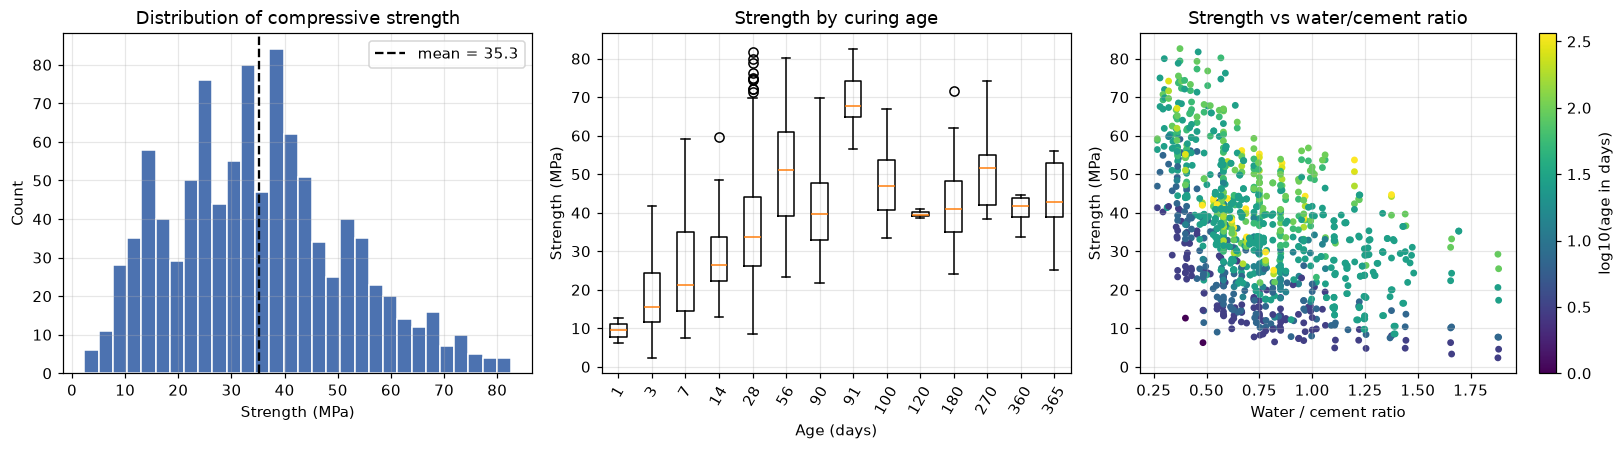

Pearson correlation with strength:
wc_ratio             -0.489
water                -0.270
fine_aggregate       -0.186
coarse_aggregate     -0.145
fly_ash              -0.081
blast_furnace_slag    0.103
age                   0.337
superplasticizer      0.344
cement                0.488


In [4]:
df["wc_ratio"] = df["water"] / df["cement"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].hist(df[TARGET], bins=30, color="#4C72B0", edgecolor="white")
ax[0].axvline(df[TARGET].mean(), color="black", ls="--", label=f"mean = {df[TARGET].mean():.1f}")
ax[0].set(title="Distribution of compressive strength", xlabel="Strength (MPa)", ylabel="Count"); ax[0].legend()

ages = sorted(df.age.unique())
ax[1].boxplot([df.loc[df.age == a, TARGET] for a in ages], tick_labels=ages)
ax[1].set(title="Strength by curing age", xlabel="Age (days)", ylabel="Strength (MPa)")
ax[1].tick_params(axis="x", rotation=60)

sc = ax[2].scatter(df.wc_ratio, df[TARGET], c=np.log10(df.age), cmap="viridis", s=12)
cb = fig.colorbar(sc, ax=ax[2]); cb.set_label("log10(age in days)")
ax[2].set(title="Strength vs water/cement ratio", xlabel="Water / cement ratio", ylabel="Strength (MPa)")
plt.tight_layout(); plt.savefig(FIG / "fig1_eda.png", bbox_inches="tight"); plt.show()

corr = df[FEATURES + ["wc_ratio", TARGET]].corr()[TARGET].drop(TARGET).sort_values()
print("Pearson correlation with strength:")
print(corr.round(3).to_string())

## 4. Train/test split grouped by mix
A random row split would put the same recipe (at different ages) in both training and test sets, so the test score would
partly measure memorisation of recipes. Here the **test set contains only recipes never seen in training**
(`GroupShuffleSplit`, about 20% of rows). The test set is used **once**, at the end.

In [5]:
X, y, groups = df[FEATURES], df[TARGET], df["mix_id"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
g_tr = groups.iloc[tr_idx]
assert set(g_tr).isdisjoint(set(groups.iloc[te_idx]))
print(f"Train: {len(X_tr)} rows / {g_tr.nunique()} mixes | Test: {len(X_te)} rows / {groups.iloc[te_idx].nunique()} mixes")
print(f"Mean strength train {y_tr.mean():.2f} MPa, test {y_te.mean():.2f} MPa")

Train: 813 rows / 341 mixes | Test: 192 rows / 86 mixes
Mean strength train 35.57 MPa, test 33.88 MPa


## 5. Candidate models and cross-validated comparison
| Model | Role | Preprocessing |
|---|---|---|
| Mean predictor | Reference: what R² = 0 looks like | none |
| Linear Regression | Baseline: assumes additive, linear effects | log(age), standardisation |
| SVR (RBF kernel) | Non-linear candidate: kernel method | log(age), standardisation |
| Random Forest | Non-linear candidate: ensemble of regression trees | none needed (trees are scale-invariant) |

**Selection rule (fixed before looking at the test set):** the candidate with the lowest grouped-CV MAE after tuning
is selected. MAE is the primary metric because it reads directly as "average error in MPa".

log(age) is used for the linear and kernel models because strength rises quickly in early days and then flattens (Section 3).
All scaling is inside a `Pipeline`, so it is fitted only on the training folds. Each model is scored with 5-fold
**GroupKFold** (no mix shared between folds) and, for comparison, ordinary random **KFold**.

In [6]:
age_pos = FEATURES.index("age")
log_age = ColumnTransformer([("log_age", FunctionTransformer(np.log1p), [age_pos])], remainder="passthrough")

def scaled(model):
    return Pipeline([("log_age", log_age), ("scale", StandardScaler()), ("model", model)])

models = {
    "Mean predictor": DummyRegressor(),
    "Linear Regression": scaled(LinearRegression()),
    "SVR (default)": scaled(SVR()),
    "Random Forest (default)": RandomForestRegressor(random_state=SEED, n_jobs=-1),
}
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
cv_group = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_random = KFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_summary(model, cv, use_groups):
    res = cross_validate(model, X_tr.values, y_tr, groups=g_tr if use_groups else None,
                         cv=cv, scoring=SCORING, n_jobs=-1)
    out = {}
    for k in SCORING:
        v = res[f"test_{k}"] * (1 if k == "R2" else -1)
        out[f"{k} mean"], out[f"{k} sd"] = v.mean(), v.std()
    return out

rows = []
for name, m in models.items():
    for split, cv, ug in [("GroupKFold", cv_group, True), ("Random KFold", cv_random, False)]:
        rows.append({"Model": name, "CV split": split, **cv_summary(m, cv, ug)})
cv_table = pd.DataFrame(rows).set_index(["Model", "CV split"]).round(3)
cv_table

MAE mean  MAE sd  RMSE mean  RMSE sd  \
Model                   CV split                                             
Mean predictor          GroupKFold      13.332   0.914     16.468    0.824   
                        Random KFold    13.304   0.530     16.442    0.608   
Linear Regression       GroupKFold       5.722   0.363      7.491    0.564   
                        Random KFold     5.602   0.186      7.333    0.241   
SVR (default)           GroupKFold       6.673   0.564      9.105    0.428   
                        Random KFold     6.307   0.258      8.670    0.419   
Random Forest (default) GroupKFold       4.547   0.510      6.252    0.767   
                        Random KFold     3.694   0.339      5.301    0.672   

                                      R2 mean  R2 sd  
Model                   CV split                      
Mean predictor          GroupKFold     -0.012  0.006  
                        Random KFold   -0.003  0.003  
Linear Regression       GroupKFold      0.787  0.041  
                        Random KFold    0.799  0.025  
SVR (default)           GroupKFold      0.690  0.016  
                        Random KFold    0.721  0.008  
Random Forest (default) GroupKFold      0.853  0.030  
                        Random KFold    0.893  0.028

In [7]:
gap = cv_table.xs("Random KFold", level=1)[["MAE mean", "R2 mean"]].join(
      cv_table.xs("GroupKFold", level=1)[["MAE mean", "R2 mean"]], lsuffix=" (random)", rsuffix=" (grouped)")
gap["MAE increase when recipes are unseen"] = gap["MAE mean (grouped)"] - gap["MAE mean (random)"]
gap.round(3)

,MAE mean (random),R2 mean (random),MAE mean (grouped),R2 mean (grouped),MAE increase when recipes are unseen
Model,,,,,
Mean predictor,13.304,-0.003,13.332,-0.012,0.028
Linear Regression,5.602,0.799,5.722,0.787,0.120
SVR (default),6.307,0.721,6.673,0.690,0.366
Random Forest (default),3.694,0.893,4.547,0.853,0.853


## 6. Hyperparameter tuning (inside grouped cross-validation)
Tuning also uses GroupKFold on the training set only, otherwise recipe leakage would return through model selection.

SVR parameters (RBF kernel):
* `C` — penalty for errors outside the tube; larger C fits the training data more closely (risk of over-fitting).
* `gamma` — kernel width; larger gamma makes each training point influence only its close neighbours (more wiggly function).
* `epsilon` — half-width of the error tube in MPa; errors smaller than epsilon are ignored.

Random Forest is tuned with the same protocol so the comparison is fair:
`n_estimators` (number of trees), `max_depth` / `min_samples_leaf` (how far each tree may grow),
`max_features` (share of features tried at each split; lower values make trees less correlated).

In [8]:
rf_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, 0.5, "sqrt"],
}
rf_search = GridSearchCV(RandomForestRegressor(random_state=SEED), rf_grid, cv=cv_group,
                         scoring="neg_mean_absolute_error", n_jobs=-1)
rf_search.fit(X_tr.values, y_tr, groups=g_tr)
print("Best RF params:", rf_search.best_params_, f"| CV MAE = {-rf_search.best_score_:.3f}")

svr_grid = {"model__C": [3, 10, 30, 100, 300, 1000], "model__gamma": ["scale", 0.03, 0.1, 0.3],
            "model__epsilon": [0.1, 1.0, 2.0]}
svr_search = GridSearchCV(scaled(SVR()), svr_grid, cv=cv_group, scoring="neg_mean_absolute_error", n_jobs=-1)
svr_search.fit(X_tr.values, y_tr, groups=g_tr)
print("Best SVR params:", svr_search.best_params_, f"| CV MAE = {-svr_search.best_score_:.3f}")

top = (pd.DataFrame(svr_search.cv_results_)
       .assign(MAE=lambda d: -d.mean_test_score, SD=lambda d: d.std_test_score)
       .sort_values("MAE")[["params", "MAE", "SD"]].head(8))
top.round(3)

Best RF params: {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 200} | CV MAE = 4.478


Best SVR params: {'model__C': 100, 'model__epsilon': 0.1, 'model__gamma': 0.1} | CV MAE = 4.308


,params,MAE,SD
38,"{'model__C': 100, 'model__epsilon': 0.1, 'mode...",4.308,0.561
24,"{'model__C': 30, 'model__epsilon': 0.1, 'model...",4.331,0.490
36,"{'model__C': 100, 'model__epsilon': 0.1, 'mode...",4.342,0.493
42,"{'model__C': 100, 'model__epsilon': 1.0, 'mode...",4.361,0.551
28,"{'model__C': 30, 'model__epsilon': 1.0, 'model...",4.375,0.459
26,"{'model__C': 30, 'model__epsilon': 0.1, 'model...",4.397,0.458
30,"{'model__C': 30, 'model__epsilon': 1.0, 'model...",4.405,0.451
40,"{'model__C': 100, 'model__epsilon': 1.0, 'mode...",4.444,0.508


In [9]:
tuned = {"SVR (tuned)": svr_search.best_estimator_, "Random Forest (tuned)": rf_search.best_estimator_}
rows = [{"Model": n, **cv_summary(m, cv_group, True)} for n, m in tuned.items()]
tuned_cv = pd.DataFrame(rows).set_index("Model").round(3)
summary_cv = pd.concat([cv_table.xs("GroupKFold", level=1), tuned_cv])
SELECTED = tuned_cv["MAE mean"].idxmin()
print("Selected by the pre-defined rule (lowest grouped-CV MAE after tuning):", SELECTED)
summary_cv

Selected by the pre-defined rule (lowest grouped-CV MAE after tuning): SVR (tuned)


,MAE mean,MAE sd,RMSE mean,RMSE sd,R2 mean,R2 sd
Model,,,,,,
Mean predictor,13.332,0.914,16.468,0.824,-0.012,0.006
Linear Regression,5.722,0.363,7.491,0.564,0.787,0.041
SVR (default),6.673,0.564,9.105,0.428,0.690,0.016
Random Forest (default),4.547,0.510,6.252,0.767,0.853,0.030
SVR (tuned),4.308,0.561,6.446,0.479,0.842,0.035
Random Forest (tuned),4.478,0.494,6.158,0.773,0.857,0.030


### Validation curves: over-fitting behaviour of both candidates
Left: SVR, varying `C` with the other tuned values fixed. Right: Random Forest, varying `min_samples_leaf`.
The gap between training and validation error shows how much each model memorises the training recipes.

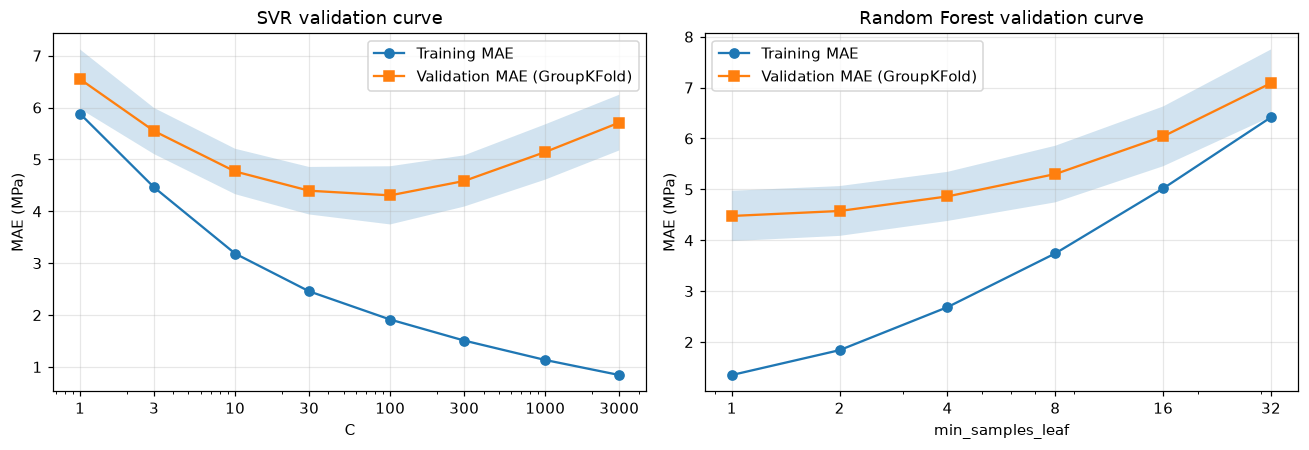

In [10]:
def vcurve(ax, est, pname, prange, xlabel, title):
    tr_s, va_s = validation_curve(est, X_tr.values, y_tr, groups=g_tr, param_name=pname, param_range=prange,
                                  cv=cv_group, scoring="neg_mean_absolute_error", n_jobs=-1)
    ax.plot(prange, -tr_s.mean(1), "o-", label="Training MAE")
    ax.plot(prange, -va_s.mean(1), "s-", label="Validation MAE (GroupKFold)")
    ax.fill_between(prange, -va_s.mean(1) - va_s.std(1), -va_s.mean(1) + va_s.std(1), alpha=0.2)
    ax.set(xscale="log", xticks=prange, xticklabels=prange, xlabel=xlabel, ylabel="MAE (MPa)", title=title)
    ax.legend()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
svr_best = svr_search.best_estimator_
vcurve(ax[0], svr_best, "model__C", [1, 3, 10, 30, 100, 300, 1000, 3000], "C", "SVR validation curve")
best = rf_search.best_params_
rf_base = RandomForestRegressor(random_state=SEED, n_estimators=best["n_estimators"],
                                max_depth=best["max_depth"], max_features=best["max_features"])
vcurve(ax[1], rf_base, "min_samples_leaf", [1, 2, 4, 8, 16, 32], "min_samples_leaf", "Random Forest validation curve")
plt.tight_layout(); plt.savefig(FIG / "fig2_validation_curves.png", bbox_inches="tight"); plt.show()

### Configuration comparison: adding the water/cement ratio as a feature
Does an engineered domain feature help? Compared with grouped CV on the training set.

In [11]:
X_tr_wc = X_tr.assign(wc_ratio=X_tr.water / X_tr.cement)
rows = []
for name, m in [("Linear Regression", scaled(LinearRegression())),
                ("SVR (tuned)", svr_search.best_estimator_),
                ("Random Forest (tuned)", RandomForestRegressor(random_state=SEED, n_jobs=-1, **rf_search.best_params_))]:
    for label, Xc in [("8 raw features", X_tr), ("+ w/c ratio", X_tr_wc)]:
        r = cross_validate(m, Xc.values, y_tr, groups=g_tr, cv=cv_group, scoring=SCORING, n_jobs=-1)
        rows.append({"Model": name, "Features": label, "MAE": -r["test_MAE"].mean(),
                     "RMSE": -r["test_RMSE"].mean(), "R2": r["test_R2"].mean()})
pd.DataFrame(rows).set_index(["Model", "Features"]).round(3)

MAE   RMSE     R2
Model                 Features                           
Linear Regression     8 raw features  5.722  7.491  0.787
                      + w/c ratio     5.733  7.501  0.787
SVR (tuned)           8 raw features  4.308  6.446  0.842
                      + w/c ratio     4.365  6.491  0.840
Random Forest (tuned) 8 raw features  4.478  6.158  0.857
                      + w/c ratio     4.491  6.155  0.858

## 7. Final evaluation on the held-out test set (unseen recipes)
Metrics: **MAE** (average error in MPa, easy to read), **RMSE** (penalises large errors more), **R²** (share of variance explained).

In [12]:
final = {
    "Linear Regression": scaled(LinearRegression()),
    "SVR (tuned)": svr_search.best_estimator_,
    "Random Forest (default)": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "Random Forest (tuned)": rf_search.best_estimator_,
}
preds, rows = {}, []
for name, m in final.items():
    m.fit(X_tr.values, y_tr)
    p = m.predict(X_te.values); preds[name] = p
    rows.append({"Model": name, "MAE": mean_absolute_error(y_te, p),
                 "RMSE": root_mean_squared_error(y_te, p), "R2": r2_score(y_te, p)})
test_table = pd.DataFrame(rows).set_index("Model").round(3)
print(f"Selected model: {SELECTED}. Test strength range {y_te.min():.1f}-{y_te.max():.1f} MPa, mean {y_te.mean():.1f} MPa")
test_table

Selected model: SVR (tuned). Test strength range 4.6-74.4 MPa, mean 33.9 MPa


,MAE,RMSE,R2
Model,,,
Linear Regression,5.444,7.003,0.795
SVR (tuned),3.805,5.324,0.882
Random Forest (default),4.523,5.963,0.852
Random Forest (tuned),4.486,5.905,0.855


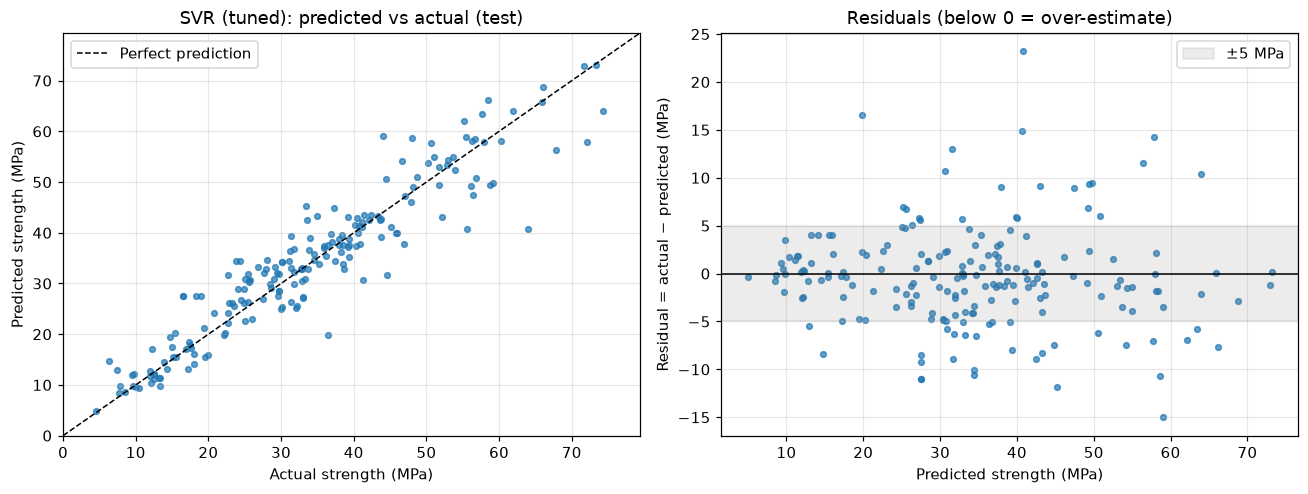

In [13]:
p = preds[SELECTED]; res = y_te.values - p
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(y_te, p, s=14, alpha=0.7)
lim = [0, max(y_te.max(), p.max()) + 5]
ax[0].plot(lim, lim, "k--", lw=1, label="Perfect prediction")
ax[0].set(xlim=lim, ylim=lim, xlabel="Actual strength (MPa)", ylabel="Predicted strength (MPa)",
          title=f"{SELECTED}: predicted vs actual (test)"); ax[0].legend()
ax[1].scatter(p, res, s=14, alpha=0.7)
ax[1].axhline(0, color="black", lw=1)
ax[1].axhspan(-5, 5, color="grey", alpha=0.15, label="±5 MPa")
ax[1].set(xlabel="Predicted strength (MPa)", ylabel="Residual = actual − predicted (MPa)",
          title="Residuals (below 0 = over-estimate)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "fig3_test_predictions.png", bbox_inches="tight"); plt.show()

### Error by curing age and over-estimation risk
Over-estimating strength is the dangerous direction: a structure could be judged stronger than it is.

In [14]:
age_band = pd.cut(X_te.age, [0, 7, 28, 100, 365], labels=["1–7 d", "14–28 d", "56–100 d", "120–365 d"])
by_age = (pd.DataFrame({"band": age_band, "abs_err": np.abs(res), "over": res < 0})
          .groupby("band", observed=True)
          .agg(rows=("abs_err", "size"), MAE=("abs_err", "mean"), share_overestimated=("over", "mean")))
print(by_age.round(3).to_string())

rows = []
for name, pr in preds.items():
    r_ = y_te.values - pr
    rows.append({"Model": name, "share over-estimated": np.mean(r_ < 0), "mean over-estimate (MPa)": -r_[r_ < 0].mean(),
                 "over by >5 MPa": np.mean(r_ < -5), "over by >10 MPa": np.mean(r_ < -10),
                 "largest over-estimate (MPa)": -r_.min()})
pd.DataFrame(rows).set_index("Model").round(3)

           rows    MAE  share_overestimated
band                                       
1–7 d        43  3.291                0.465
14–28 d      98  4.520                0.571
56–100 d     40  3.163                0.625
120–365 d    11  1.781                0.727


,share over-estimated,mean over-estimate (MPa),over by >5 MPa,over by >10 MPa,largest over-estimate (MPa)
Model,,,,,
Linear Regression,0.562,5.610,0.255,0.078,19.839
SVR (tuned),0.568,3.660,0.156,0.036,15.006
Random Forest (default),0.568,4.562,0.240,0.052,12.897
Random Forest (tuned),0.568,4.532,0.224,0.057,12.630


## 8. What drives the predictions? (permutation importance on the test set)
Each feature is shuffled in turn; the increase in MAE shows how much the model relies on it.

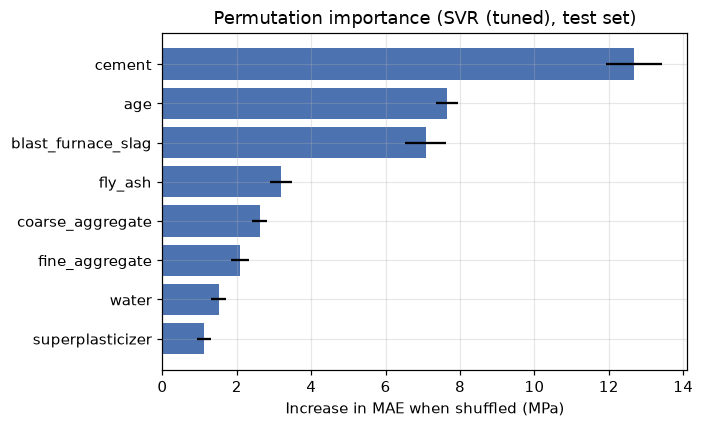

cement                12.686
age                    7.648
blast_furnace_slag     7.075
fly_ash                3.190
coarse_aggregate       2.612
fine_aggregate         2.092
water                  1.510
superplasticizer       1.115
dtype: float64

In [15]:
pi = permutation_importance(final[SELECTED], X_te.values, y_te, n_repeats=30,
                            random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
err = pd.Series(pi.importances_std, index=FEATURES)[imp.index]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp.index, imp.values, xerr=err.values, color="#4C72B0")
ax.set(xlabel="Increase in MAE when shuffled (MPa)", title=f"Permutation importance ({SELECTED}, test set)")
plt.tight_layout(); plt.savefig(FIG / "fig4_permutation_importance.png", bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(3)

## 9. Extra check (not used for model selection)
Two other tree ensembles, run with the same grouped CV on the training set, to see whether the conclusion
"several non-linear models reach a similar error on unseen recipes" holds. Mentioned only as future work in the report.

In [16]:
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
extra = {
    "Extra Trees (500 trees)": ExtraTreesRegressor(n_estimators=500, random_state=SEED, n_jobs=-1),
    "Gradient Boosting (500, lr=0.05, depth=4)": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED),
}
pd.DataFrame([{"Model": n, **cv_summary(m, cv_group, True)} for n, m in extra.items()]).set_index("Model").round(3)

,MAE mean,MAE sd,RMSE mean,RMSE sd,R2 mean,R2 sd
Model,,,,,,
Extra Trees (500 trees),4.030,0.515,5.839,0.711,0.872,0.027
"Gradient Boosting (500, lr=0.05, depth=4)",4.185,0.342,5.946,0.398,0.868,0.014
